# Practitioner–Researcher Gap: Analysis Notebook

1. **Data processing**
2. **Descriptive stats + journal-label validity tests (with significance tests)**
3. **Which words are more frequent/distinctive by author status** (log-odds keyness + logistic regression classifier)
4. **Which words co-occur with each other / with the focal concept** (collocation / co-occurrence + temporal change)
5. **Semantic similarity of abstracts** (SBERT: centroid/dispersion + PCA visualization + permutation tests)

In [1]:
# If running locally and missing packages, uncomment as needed:
# !pip -q install pandas numpy scipy scikit-learn nltk xlrd sentence-transformers tqdm matplotlib

import re
import glob
import math
from collections import Counter, defaultdict

import numpy as np
import pandas as pd

from scipy.stats import chi2_contingency, kruskal, fisher_exact

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics.pairwise import cosine_similarity

import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.stem.snowball import SnowballStemmer

# NLTK downloads
try:
    _ = stopwords.words("english")
except LookupError:
    import ssl
    try:
        _create_unverified_https_context = ssl._create_unverified_context
    except AttributeError:
        pass
    else:
        ssl._create_default_https_context = _create_unverified_https_context
    nltk.download("stopwords")
    nltk.download("punkt")

stemmer = SnowballStemmer("english")
# setting to display 3 decimal points
pd.options.display.float_format = "{:.3f}".format

## 1. Data processing: load spreadsheets

In [2]:
# This notebook expects the 10 WoS-export .xls files (one per journal) in a directory called "data" 
# alongside this .ipynb file.
# If you are using the provided ZIP, set ZIP_PATH accordingly and the notebook will unzip to DATA_DIR.

ZIP_PATH = "WoS_practitioner_researcher_coded.zip"  # update if needed
DATA_DIR_CANDIDATES = [
    "./WoS_practitioner_researcher_coded",
    "../data",
    "./data",
]

# If the ZIP exists in the working directory but isn't extracted yet, extract it.
import os, zipfile
if os.path.exists(ZIP_PATH):
    target_dir = "./WoS_practitioner_researcher_coded"
    if not os.path.exists(target_dir):
        os.makedirs(target_dir, exist_ok=True)
        with zipfile.ZipFile(ZIP_PATH, "r") as z:
            z.extractall(target_dir)
        print(f"Extracted {ZIP_PATH} -> {target_dir}")

# Find .xls files
paths = []
for d in DATA_DIR_CANDIDATES:
    cand = sorted(glob.glob(os.path.join(d, "*.xls")))
    if len(cand) >= 10:
        paths = cand
        print("Using data directory:", d)
        break

assert len(paths) >= 10, f"Expected >=10 .xls files; found {len(paths)}. Check ZIP_PATH / DATA_DIR_CANDIDATES."

paths

Using data directory: ../data


['../data/1-CRL.xls',
 '../data/10-LQ.xls',
 '../data/2-LRTS.xls',
 '../data/3-Portal.xls',
 '../data/4-ITL.xls',
 '../data/5-RUSQ.xls',
 '../data/6-LISR.xls',
 '../data/7-JDoc.xls',
 '../data/8-GIQ.xls',
 '../data/9-IR.xls']

In [3]:
# group journals into "Librarian journal" or "Non-librarian journal"

def journal_type_from_filename(path: str) -> str:
    """
    Files 1-5 are 'Librarian journals'
    Files 6-10 are 'Non-librarian journals'
    """
    base = path.split("/")[-1]
    m = re.match(r"(\d+)-", base)
    if not m:
        return "unknown"
    prefix = int(m.group(1))
    if 1 <= prefix <= 5:
        return "librarian_journal"
    if 6 <= prefix <= 10:
        return "non_librarian_journal"
    return "unknown"

def journal_short_from_filename(path: str) -> str:
    base = path.split("/")[-1]
    # "1-CRL.xls" -> "CRL"
    return re.sub(r"^\d+-", "", base).replace(".xls", "")

# get column names
def _find_col(df: pd.DataFrame, candidates):
    cols_lower = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in cols_lower:
            return cols_lower[cand.lower()]
    # fuzzy contains
    for c in df.columns:
        cl = str(c).lower()
        for cand in candidates:
            if cand.lower() in cl:
                return c
    return None

# not necessary, but it's nice to see best practices in action
def standardize_author_status(x: str) -> str:
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    # normalize common variants
    if s in {"librarian", "practitioner"}:
        return "Librarian"
    if s in {"non-librarian", "nonlibrarian", "researcher", "academic", "non librarian"}:
        return "Non-librarian"
    if s in {"collaboration", "collaborative", "mixed"}:
        return "Collaboration"
    # leave as-is but title-case, so issues are visible
    return str(x).strip()

def load_one_xls(path: str) -> pd.DataFrame:
    # .xls typically requires xlrd
    df = pd.read_excel(path, engine="xlrd")
    df["source_file"] = path.split("/")[-1]
    df["journal_short"] = journal_short_from_filename(path)
    df["journal_type_label"] = journal_type_from_filename(path)
    return df

dfs = []
for p in paths:
    dfs.append(load_one_xls(p))

raw = pd.concat(dfs, ignore_index=True)
raw.shape, raw.columns[:10]

((237, 78),
 Index(['Author Status', 'Author Status Notes', 'DOI Link', 'Publication Type',
        'Authors', 'Book Authors', 'Book Editors', 'Book Group Authors',
        'Author Full Names', 'Book Author Full Names'],
       dtype='object'))

In [4]:
# identify key columns
abstract_col = _find_col(raw, ["Abstract", "AB"])
# year_col = _find_col(raw, ["Publication Year", "PY", "Year", "Year Published"])
year_col = _find_col(raw, ["Publication Year"])
author_status_col = _find_col(raw, ["Author Status", "AuthorStatus"])

print("Detected columns:")
print("  Abstract:", abstract_col)
print("  Year:", year_col)
print("  Author Status:", author_status_col)

# if Author Status wasn't detected by name, default to first column (column A)
if author_status_col is None:
    author_status_col = raw.columns[0]
    print(f"Author Status not found by name; using first column as status: {author_status_col}")

# build standardized working frame
df = raw.copy()
df = df.rename(columns={
    abstract_col: "abstract",
    year_col: "year",
    author_status_col: "author_status_raw"
})

df["author_status"] = df["author_status_raw"].apply(standardize_author_status)
df["year"] = pd.to_numeric(df["year"], errors="coerce").astype("Int64")

# basic cleaning
df["abstract"] = df["abstract"].fillna("").astype(str).str.strip()
df = df[df["abstract"] != ""].copy()

df[["journal_short", "journal_type_label", "year", "author_status_raw", "author_status", "abstract"]].head()

Detected columns:
  Abstract: Abstract
  Year: Publication Year
  Author Status: Author Status


,journal_short,journal_type_label,year,author_status_raw,author_status,abstract
0,CRL,librarian_journal,2016,Librarian,Librarian,This study analyzed digital item metadata and ...
1,CRL,librarian_journal,2011,Librarian,Librarian,Content-enriched metadata in bibliographic rec...
2,CRL,librarian_journal,2004,Librarian,Librarian,To be successful in the university environment...
3,CRL,librarian_journal,2019,Non-librarian,Non-librarian,We examine common and unique metadata requirem...
4,CRL,librarian_journal,2020,Collaboration,Collaboration,An earlier version of this manuscript was pres...


## 2. Descriptives + journal-label validity tests (with significance tests)

In [5]:
# counts by author status

status_counts = df["author_status"].value_counts(dropna=False).rename_axis("author_status").reset_index(name="n")
status_counts

,author_status,n
0,Non-librarian,133
1,Librarian,77
2,Collaboration,27


In [6]:
# descriptive statistics for abstract word length
df["abstract_words"] = df["abstract"].str.findall(r"[A-Za-z]+").str.len()

desc_overall = df["abstract_words"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).to_frame("abstract_words")
desc_by_status = df.groupby("author_status")["abstract_words"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])

desc_overall, desc_by_status

(       abstract_words
 count         237.000
 mean          172.671
 std            72.968
 min            36.000
 10%            92.600
 25%           119.000
 50%           155.000
 75%           226.000
 90%           266.000
 max           483.000,
                 count    mean    std    min     10%     25%     50%     75%  \
 author_status                                                                 
 Collaboration  27.000 163.889 53.163 86.000 106.200 133.000 149.000 190.500   
 Librarian      77.000 129.468 48.733 36.000  79.600  96.000 123.000 151.000   
 Non-librarian 133.000 199.466 75.943 69.000 101.200 142.000 201.000 242.000   
 
                   90%     max  
 author_status                  
 Collaboration 249.200 293.000  
 Librarian     191.600 281.000  
 Non-librarian 286.400 483.000  )

In [7]:
# check coding vs journal-type labels (1–5 = librarian journals; 6–10 = non-librarian journals)
ct = pd.crosstab(df["journal_type_label"], df["author_status"], dropna=False)
ct

author_status,Collaboration,Librarian,Non-librarian
journal_type_label,,,
librarian_journal,20,73,33
non_librarian_journal,7,4,100


In [8]:
# and show journal-type labels as proportions
ct_prop = ct.div(ct.sum(axis=1), axis=0).round(3)
ct_prop

author_status,Collaboration,Librarian,Non-librarian
journal_type_label,,,
librarian_journal,0.159,0.579,0.262
non_librarian_journal,0.063,0.036,0.901


In [9]:
# journal-by-journal breakdown (for RQ1 table)
journal_breakdown = (
    df.groupby(["journal_short", "journal_type_label", "author_status"])
      .size()
      .reset_index(name="n")
)

journal_pivot = journal_breakdown.pivot_table(
    index=["journal_short", "journal_type_label"],
    columns="author_status",
    values="n",
    fill_value=0
).reset_index()

journal_pivot["total"] = journal_pivot[[c for c in journal_pivot.columns if c not in ["journal_short","journal_type_label"]]].sum(axis=1)
journal_pivot

author_status,journal_short,journal_type_label,Collaboration,Librarian,Non-librarian,total
0,CRL,librarian_journal,3.000,6.000,2.000,11.000
1,GIQ,non_librarian_journal,1.000,1.000,9.000,11.000
2,IR,non_librarian_journal,1.000,0.000,20.000,21.000
3,ITL,librarian_journal,8.000,23.000,21.000,52.000
4,JDoc,non_librarian_journal,3.000,3.000,58.000,64.000
5,LISR,non_librarian_journal,1.000,0.000,11.000,12.000
6,LQ,non_librarian_journal,1.000,0.000,2.000,3.000
7,LRTS,librarian_journal,9.000,36.000,9.000,54.000
8,Portal,librarian_journal,0.000,6.000,0.000,6.000
9,RUSQ,librarian_journal,0.000,2.000,1.000,3.000


In [10]:
# Chi-squared significance tests
# Are author-status categories distributed differently across journal-type labels?
#     (journal_type_label x author_status) -> chi-square test of independence.

ct = pd.crosstab(df["journal_type_label"], df["author_status"])
chi2, p, dof, expected = chi2_contingency(ct)
chi2_out = pd.DataFrame(
    {"chi2":[chi2], "dof":[dof], "p_value":[p], "n":[ct.to_numpy().sum()]}
)
chi2_out

,chi2,dof,p_value,n
0,101.299,2,0.000,237


In [11]:
# Calculate effect size (Cramér's V)

n = ct.to_numpy().sum()
k = min(ct.shape)

cramers_v = np.sqrt(chi2 / (n * (k - 1)))

print("Chi-square:", chi2)
print("p-value:", p)
print("Cramér's V:", cramers_v)
print("Cramér's V > 0.50 indicates a strong association")

Chi-square: 101.29871990272991
p-value: 1.007540381072059e-22
Cramér's V: 0.6537742416792272
Cramér's V > 0.50 indicates a strong association


In [1]:
# Test the difference in collaborative article proportions between journal types
# Use two-proportion z-test

from statsmodels.stats.proportion import proportions_ztest

# collaborative article counts [librarian, non-librarian]
collab_counts = [20, 7]

# total articles by journal type [librarian, non-librarian]
totals = [126, 111]

# two-proportion z-test
z_stat, p_val = proportions_ztest(collab_counts, totals)

print("Two-proportion z-test for collaborative article proportions")
print(f"z = {z_stat:.3f}, p = {p_val:.3f}")

# calculate the proportions
p_practitioner = collab_counts[0] / totals[0]
p_researcher = collab_counts[1] / totals[1]

print(f"Practitioner journals: {p_practitioner:.3%}")
print(f"Researcher journals: {p_researcher:.3%}")

Two-proportion z-test for collaborative article proportions
z = 2.313, p = 0.021
Practitioner journals: 15.873%
Researcher journals: 6.306%


In [12]:
# Do abstract lengths differ by author status?
#     Abstract word counts are typically skewed -> use Kruskal–Wallis (nonparametric).
groups = [g["abstract_words"].dropna().to_numpy()
          for _, g in df.groupby("author_status") if len(g) > 0]
labels = [name for name, g in df.groupby("author_status") if len(g) > 0]
kw_stat, kw_p = kruskal(*groups)
pd.DataFrame({"test":["Kruskal-Wallis"], "stat":[kw_stat], "p_value":[kw_p], "groups":[", ".join(labels)]})

,test,stat,p_value,groups
0,Kruskal-Wallis,48.373,0.000,"Collaboration, Librarian, Non-librarian"


In [13]:
# Optional: check whether the abstract-length divergence is more 'journal-driven'
#     by repeating the same test at journal level (journal_short groups instead of author_status) 
j_groups = [g["abstract_words"].dropna().to_numpy()
            for _, g in df.groupby("journal_short") if len(g) > 0]
j_labels = [name for name, g in df.groupby("journal_short") if len(g) > 0]
j_kw_stat, j_kw_p = kruskal(*j_groups)
pd.DataFrame({"test":["Kruskal-Wallis"], "stat":[j_kw_stat], "p_value":[j_kw_p], "groups":[f"{len(j_labels)} journals"]})

,test,stat,p_value,groups
0,Kruskal-Wallis,105.797,0.000,10 journals


## 3. Distinctive words by author status (RQ2)

This section answers: *Which words are unusually common in librarian vs non‑librarian abstracts?* It includes (a) descriptive “keyness” via log‑odds and (b) a predictive model (logistic regression) with accuracy + interpretable coefficients.

In [14]:
# use NLTK stopword list; see https://gist.github.com/sebleier/554280
STOP = set(stopwords.words("english"))

# optional: set domain-specific stopwords to prevent trivial top terms
DOMAIN_STOP = {"metadata"}  # add more if needed: {"metadata","study","paper","research"}
STOP_ALL = STOP.union(DOMAIN_STOP)

TOKEN_RE = re.compile(r"[A-Za-z][A-Za-z\-']+")

# tokenize using lowercase, length > 2, filter the stopwords
def tokenize(text: str):
    toks = [t.lower() for t in TOKEN_RE.findall(text)]
    toks = [t for t in toks if t not in STOP_ALL and len(t) > 2]
    return toks

def make_ngrams(tokens, n=2):
    return [" ".join(tokens[i:i+n]) for i in range(len(tokens)-n+1)]

In [15]:
# n-gram analyses was helpful for understanding and exploring the dataset 
# but was not reported in the manuscript

WORK = df.copy()

WORK["tokens"] = WORK["abstract"].apply(tokenize)
WORK["bigrams"] = WORK["tokens"].apply(lambda t: make_ngrams(t, 2))
WORK["trigrams"] = WORK["tokens"].apply(lambda t: make_ngrams(t, 3))

WORK[["author_status", "year", "tokens", "bigrams", "trigrams"]].head()

,author_status,year,tokens,bigrams,trigrams
0,Librarian,2016,"[study, analyzed, digital, item, keywords, int...","[study analyzed, analyzed digital, digital ite...","[study analyzed digital, analyzed digital item..."
1,Librarian,2011,"[content-enriched, bibliographic, records, con...","[content-enriched bibliographic, bibliographic...","[content-enriched bibliographic records, bibli..."
2,Librarian,2004,"[successful, university, environment, digital,...","[successful university, university environment...","[successful university environment, university..."
3,Non-librarian,2019,"[examine, common, unique, requirements, levels...","[examine common, common unique, unique require...","[examine common unique, common unique requirem..."
4,Collaboration,2020,"[earlier, version, manuscript, presented, auth...","[earlier version, version manuscript, manuscri...","[earlier version manuscript, version manuscrip..."


### 3.1 Log-odds keyness (symmetric vs informative Dirichlet priors)

The *informative* prior uses the overall corpus frequency of each term as a baseline (cf. Monroe et al.), so that very common words are not over-weighted simply because they’re common. The hyperparameter **alpha0** controls the *strength* of that prior:

- Smaller **alpha0** → prior is weak → results behave more like raw log-odds.
- Larger **alpha0** → prior dominates more strongly → results shrink toward the corpus baseline.

Best practice is to (a) tie alpha0 score to a concrete interpretation (“equivalent prior sample size”) and (b) do a short **sensitivity check** showing that the top terms are reasonably stable across a plausible range.


In [16]:
from collections import Counter

def get_group_counts(df, token_col, group_value, group_col="author_status"):
    """
    Count token frequencies within a group when df[token_col] already contains lists of tokens.
    Expected: df[token_col] is an iterable (list) of tokens per row.
    """
    subset = df.loc[df[group_col] == group_value, token_col].dropna()

    counts = Counter()
    for toks in subset:
        # toks should be a list/iterable of tokens
        counts.update(toks)

    return counts

In [17]:
# Technique 1: Symmetric Dirichlet Prior (used for comparison of techniques; not used for paper)
# assumes that before seeing the data, every word is equally likely
# every term gets the same small pseudo-count α
# rare words and common words are treated the same a priori
# there is light smoothing, more sensitive to rare terms, and can highlight niche vocabulary
# main drawback: in small and uneven corpora (like ours), rare terms can look artificially distinctive

# get unigram counts by group
uni_counts = {g: get_group_counts(WORK, "tokens", g) for g in WORK["author_status"].dropna().unique()}

def log_odds_symmetric(counts_a: Counter, counts_b: Counter, alpha=0.01):

    vocab = sorted(set(counts_a) | set(counts_b))

    n_a = sum(counts_a.values())
    n_b = sum(counts_b.values())

    rows = []

    V = len(vocab)

    for w in vocab:
        a = counts_a.get(w, 0)
        b = counts_b.get(w, 0)

        pa = (a + alpha) / (n_a + alpha * V)
        pb = (b + alpha) / (n_b + alpha * V)

        lo = math.log(pa / (1 - pa)) - math.log(pb / (1 - pb))
        var = 1/(a + alpha) + 1/(b + alpha)
        z = lo / math.sqrt(var)

        rows.append((w, a, b, lo, z))

    out = pd.DataFrame(
        rows,
        columns=["term", "count_A", "count_B", "log_odds_sym", "z_sym"]
    )

    return out.sort_values("z_sym", ascending=False)

In [18]:
# Technique 2: Informative Dirichlet Prior (used for paper; cf. Monroe et alia)
# assumes before looking at groups, we already know which words are common in the whole corpus
# prior for each word is proportional to its overall frequency
# frequent words get more prior weight; rare words get little prior mass
# stronger regularization, downweights idiosyncratic terms, and highlights systematic differences
# main benefit: much more stable when group sizes differ (ours do) and/or abstract lengths differ (ours do)

def log_odds_informative(counts_a: Counter,
                        counts_b: Counter,
                        prior: Counter,
                        alpha0=1000.0):

    vocab = sorted(set(counts_a) | set(counts_b) | set(prior))

    prior_total = sum(prior.values())

    # term-specific priors
    alpha = {
        w: alpha0 * (prior.get(w, 0) / prior_total)
        for w in vocab
    }

    n_a = sum(counts_a.values())
    n_b = sum(counts_b.values())

    rows = []

    for w in vocab:

        a = counts_a.get(w, 0)
        b = counts_b.get(w, 0)
        aw = alpha[w]

        pa = (a + aw) / (n_a + alpha0)
        pb = (b + aw) / (n_b + alpha0)

        lo = math.log(pa / (1 - pa)) - math.log(pb / (1 - pb))
        var = 1/(a + aw) + 1/(b + aw)
        z = lo / math.sqrt(var)

        rows.append((w, a, b, aw, lo, z))

    out = pd.DataFrame(
        rows,
        columns=["term", "count_A", "count_B", "alpha_w", "log_odds_inf", "z_inf"]
    )

    return out.sort_values("z_inf", ascending=False)

In [19]:
def one_vs_rest_both(counts_by_group, group, prior, alpha=0.01, alpha0=1000):

    A = counts_by_group[group]

    rest = Counter()
    for g, c in counts_by_group.items():
        if g != group:
            rest.update(c)

    sym = log_odds_symmetric(A, rest, alpha=alpha)
    inf = log_odds_informative(A, rest, prior, alpha0=alpha0)

    merged = (
        sym.merge(
            inf,
            on=["term", "count_A", "count_B"],
            how="inner"
        )
        .sort_values("z_inf", ascending=False)
    )

    return merged

In [20]:
from collections import Counter
from nltk import bigrams

def extract_bigrams(tokens):
    return list(bigrams(tokens))


# Build bigram column if it doesn't exist
if "bigrams" not in WORK.columns:
    WORK["bigrams"] = WORK["tokens"].apply(extract_bigrams)


# Group-wise bigram counts
bi_counts = {
    g: Counter(
        t for row in WORK.loc[WORK["author_status"] == g, "bigrams"].dropna()
        for t in row
    )
    for g in WORK["author_status"].dropna().unique()
}

In [21]:
# build priors
prior_uni = Counter()
for c in uni_counts.values():
    prior_uni.update(c)

In [22]:
# build priors
prior_bi = Counter()
for c in bi_counts.values():
    prior_bi.update(c)

In [23]:
# compare the two techniques
# z_sym: distinctiveness under symmetric prior
# z_inf: distinctiveness under informative prior

for g in sorted(uni_counts.keys()):

    res = one_vs_rest_both(
        uni_counts,
        g,
        prior_uni,
        alpha=0.01,
        alpha0=460
    )

    print(f"\n=== {g}: Top Distinctive Terms ===")

    display(
        res[[
            "term",
            "count_A",
            "count_B",
            "z_sym",
            "z_inf"
        ]].head(25)
    )


=== Collaboration: Top Distinctive Terms ===


,term,count_A,count_B,z_sym,z_inf
0,grant,12,4,5.516,5.212
1,competencies,9,3,4.776,4.513
2,cataloging,28,93,4.112,3.664
3,implementation,10,16,4.005,3.604
4,pdf,6,4,3.857,3.552
5,document,8,11,3.800,3.431
6,proposals,5,2,3.587,3.362
9,referencing,5,1,3.377,3.272
7,shared,7,10,3.505,3.162
8,access,24,87,3.460,3.083



=== Librarian: Top Distinctive Terms ===


,term,count_A,count_B,z_sym,z_inf
0,cataloging,58,63,5.758,5.466
1,library,77,100,5.740,5.442
2,libraries,57,66,5.440,5.161
3,marc,26,15,5.175,4.957
4,catalogers,19,6,4.869,4.736
5,university,25,17,4.814,4.597
6,resources,35,34,4.806,4.567
8,name,15,4,4.352,4.258
7,process,30,30,4.367,4.149
9,discovery,26,24,4.265,4.055



=== Non-librarian: Top Distinctive Terms ===


,term,count_A,count_B,z_sym,z_inf
1,purpose,78,10,4.340,4.235
0,analysis,89,14,4.359,4.222
3,cultural,53,4,3.832,3.851
2,user,69,10,3.944,3.830
4,social,63,9,3.784,3.677
6,image,49,4,3.669,3.668
5,knowledge,65,10,3.752,3.636
7,approach,82,17,3.664,3.521
8,methodology,51,6,3.573,3.500
9,originality,50,6,3.524,3.449


In [24]:
# ------------------------------
# Build Table 6: Top log-odds terms (one-vs-rest, informative prior)
# ------------------------------
logodds_rows = []

for g in sorted(uni_counts.keys()):
    res = one_vs_rest_both(
        uni_counts,
        g,
        prior_uni,
        alpha=0.01,
        # alpha0=1000
        alpha0=460
    )

    top = res[["term", "count_A", "count_B", "z_sym", "z_inf"]].head(25).copy()
    top.insert(0, "author_status", g)
    logodds_rows.append(top)

    display(
        res[[
            "term",
            "count_A",
            "count_B",
            "z_sym",
            "z_inf"
        ]].head(10)
    )

logodds_df = pd.concat(logodds_rows, ignore_index=True)
# logodds_df[:4]

,term,count_A,count_B,z_sym,z_inf
0,grant,12,4,5.516,5.377
1,competencies,9,3,4.776,4.655
2,cataloging,28,93,4.112,3.915
3,implementation,10,16,4.005,3.818
4,pdf,6,4,3.857,3.713
5,document,8,11,3.800,3.627
6,proposals,5,2,3.587,3.482
7,shared,7,10,3.505,3.344
9,referencing,5,1,3.377,3.331
8,access,24,87,3.460,3.297


,term,count_A,count_B,z_sym,z_inf
0,cataloging,58,63,5.758,5.632
1,library,77,100,5.740,5.614
2,libraries,57,66,5.440,5.320
3,marc,26,15,5.175,5.079
4,catalogers,19,6,4.869,4.813
5,university,25,17,4.814,4.718
6,resources,35,34,4.806,4.702
8,name,15,4,4.352,4.314
7,process,30,30,4.367,4.272
9,discovery,26,24,4.265,4.173


,term,count_A,count_B,z_sym,z_inf
0,analysis,89,14,4.359,4.293
1,purpose,78,10,4.340,4.292
2,user,69,10,3.944,3.890
3,cultural,53,4,3.832,3.854
4,social,63,9,3.784,3.734
5,knowledge,65,10,3.752,3.696
6,image,49,4,3.669,3.679
7,approach,82,17,3.664,3.593
8,methodology,51,6,3.573,3.542
9,originality,50,6,3.524,3.491


In [25]:
# --- alpha0 sensitivity check ---
# Treat alpha0 as an 'equivalent prior sample size' (pseudo-count mass) over the vocabulary.
# A reasonable range is often on the order of: 0.5x to 10x the average document length, or (more robust) a few multiples of the
# median token count per group. Here we use a small grid to show stability.

# Compute a rough scale using median abstract token count
med_tokens = WORK["tokens"].apply(len).median()
# alpha0_grid = [int(med_tokens), int(2*med_tokens), int(5*med_tokens), 1000]

# tie alpha0 to abstract length instead of arbitrary value of 1000
alpha0_grid = [
    int(1 * med_tokens),    # ~1x median length
    int(2 * med_tokens),    # ~2x median length
    int(5 * med_tokens),    # ~5x median length
    int(10 * med_tokens),   # “large” but interpretable
    int(50 * med_tokens),   # “very large” stress test
]

def top_terms_for_alpha0(alpha0, prior_counts, group="Librarian", topn=20):
    out = one_vs_rest_both(uni_counts, group, prior_counts, alpha=0.01, alpha0=alpha0)
    # out is DataFrame with z-scores; make sure it exists (from your earlier cell)
    # keep the most distinctive terms for the group (positive z)
    return out.sort_values("z_inf", ascending=False).head(topn)[["term","z_inf"]]

# iterate through alpha0_grid to test different alpha0 values; are they consistent or different?
top_by_alpha0 = {a0: top_terms_for_alpha0(a0, prior_uni, group="Librarian", topn=15) for a0 in alpha0_grid}
top_by_alpha0

{92:           term  z_inf
 0   cataloging  5.755
 1      library  5.742
 2    libraries  5.438
 3         marc  5.168
 4   catalogers  4.866
 5   university  4.807
 6    resources  4.802
 7      process  4.364
 8         name  4.351
 9    discovery  4.261
 10       music  3.851
 11   authority  3.851
 12         ead  3.758
 13    headings  3.634
 14  librarians  3.614,
 184:           term  z_inf
 0   cataloging  5.723
 1      library  5.709
 2    libraries  5.408
 3         marc  5.145
 4   catalogers  4.853
 5   university  4.784
 6    resources  4.776
 8         name  4.342
 7      process  4.340
 9    discovery  4.238
 10       music  3.840
 11   authority  3.840
 12         ead  3.794
 13    headings  3.619
 14  librarians  3.596,
 460:           term  z_inf
 0   cataloging  5.632
 1      library  5.614
 2    libraries  5.320
 3         marc  5.079
 4   catalogers  4.813
 5   university  4.718
 6    resources  4.702
 8         name  4.314
 7      process  4.272
 9    discovery  4

In [26]:
# Get alpha0 values from robustness testing

print("Median tokens:", med_tokens)
print("alpha0 grid:", alpha0_grid)

# We will use alpha0 = 460 = 5x median length
# Which is not too strong as to penalize rare but meaningful words

Median tokens: 92.0
alpha0 grid: [92, 184, 460, 920, 4600]


### 3.2 Logistic regression classifier (with prediction accuracy)

Can we reliably distinguish librarian vs non‑librarian abstracts from text features? If yes, which terms drive the separation?

> Note: The results of the classifier are left in this notebook as an additional exploration of the data, however the classifier is not part of the manuscript. We chose to use the log-odds analysis to report on more frequent terms in librarian vs. non-librarian articles

In [27]:
# Keep only clear binary classes for supervised classification.
train = WORK[WORK["author_status"].isin(["Librarian", "Non-librarian"])].copy()
test = WORK[WORK["author_status"] == "Collaboration"].copy()

y = train["author_status"].values

# TF-IDF with unigrams + bigrams for interpretability
vec = TfidfVectorizer(
    ngram_range=(1,2),
    min_df=2,
    max_df=0.90,
    stop_words="english"
)

X = vec.fit_transform(train["abstract"].values)

clf = LogisticRegression(max_iter=2000, solver="liblinear")  # stable for small/medium corpora

# 5-fold stratified CV accuracy (reviewer request: report predictive performance)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_acc = cross_val_score(clf, X, y, cv=cv, scoring="accuracy")
pd.DataFrame({"cv_fold_accuracy": cv_acc, "mean":[cv_acc.mean()]*len(cv_acc), "sd":[cv_acc.std(ddof=1)]*len(cv_acc)})

# Fit on all training data (for coefficients + collaboration predictions)
clf.fit(X, y)

# In-sample training accuracy (less important than CV, but useful to report transparently)
train_pred = clf.predict(X)
train_acc = accuracy_score(y, train_pred)
print("Training accuracy", train_acc)

Training accuracy 0.9238095238095239


In [28]:
# Table with cross-validation scores

# cv_acc is the array returned by cross_val_score
cv_table = pd.DataFrame({
    "Fold": range(1, len(cv_acc) + 1),
    "Accuracy": cv_acc
})

# Optional: add summary rows (nice for reporting)
cv_summary = pd.DataFrame({
    "Fold": ["Mean", "SD"],
    "Accuracy": [cv_acc.mean(), cv_acc.std(ddof=1)]
})

cv_table_display = pd.concat([cv_table, cv_summary], ignore_index=True)

cv_table_display

,Fold,Accuracy
0,1,0.690
1,2,0.667
2,3,0.762
3,4,0.690
4,5,0.690
5,Mean,0.700
6,SD,0.036


In [29]:
# Predict Collaboration abstracts to see which side they 'lean' toward
if len(test) > 0:
    X_test = vec.transform(test["abstract"].values)
    pred = clf.predict(X_test)
    test_out = test[["journal_short","journal_type_label","year","author_status"]].copy()
    test_out["predicted_label"] = pred
    display(test_out["predicted_label"].value_counts())
    display(pd.crosstab(test_out["journal_type_label"], test_out["predicted_label"], normalize="index").round(3))
else:
    print("No Collaboration abstracts available to predict in this dataset subset.")

# Coefficients for interpretability: which terms push toward Librarian vs Non-librarian?
feature_names = np.array(vec.get_feature_names_out())
coefs = clf.coef_.ravel()

# Determine which class is "positive" in coefficients
pos_class = clf.classes_[1]
neg_class = clf.classes_[0]

top_pos = pd.DataFrame({"term": feature_names[np.argsort(coefs)[-25:]][::-1],
                        "coef": np.sort(coefs)[-25:][::-1]})
top_neg = pd.DataFrame({"term": feature_names[np.argsort(coefs)[:25]],
                        "coef": np.sort(coefs)[:25]})

print(f"Positive class = {pos_class} (terms with positive coefficients)")
display(top_pos)
print(f"Negative class = {neg_class} (terms with negative coefficients)")
display(top_neg)

predicted_label
Non-librarian    19
Librarian         8
Name: count, dtype: int64

predicted_label,Librarian,Non-librarian
journal_type_label,,
librarian_journal,0.400,0.600
non_librarian_journal,0.000,1.000


Positive class = Non-librarian (terms with positive coefficients)


,term,coef
0,information,0.694
1,data,0.691
2,social,0.642
3,analysis,0.623
4,user,0.581
5,cultural,0.568
6,knowledge,0.546
7,retrieval,0.524
8,heritage,0.500
9,value,0.496


Negative class = Librarian (terms with negative coefficients)


,term,coef
0,library,-1.108
1,marc,-0.891
2,cataloging,-0.888
3,catalogers,-0.789
4,libraries,-0.751
5,university,-0.659
6,discovery,-0.619
7,repository,-0.562
8,process,-0.521
9,librarians,-0.492


## 4. Collocation / co-occurrence analysis (RQ3)


In [30]:
# Updated collocation functions, currently being used to generate the analysis for the manuscript

import re
import math
from itertools import combinations
from collections import Counter, defaultdict

import pandas as pd

# --- Optional: sentence splitter that doesn't require nltk ---
_SENT_SPLIT_RE = re.compile(r'(?<=[.!?])\s+')

def simple_sentence_split(text: str):
    if not isinstance(text, str) or not text.strip():
        return []
    # crude but effective for abstracts
    return [s.strip() for s in _SENT_SPLIT_RE.split(text.strip()) if s.strip()]

def default_tokenize(text: str):
    """
    Lightweight tokenizer:
    - lowercase
    - keep a-z only
    - split on whitespace
    """
    if not isinstance(text, str):
        return []
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = text.split()
    return tokens

def build_doc_frequency(df: pd.DataFrame, text_col: str, tokenize_fn=default_tokenize):
    """
    Document frequency at the ABSTRACT level: in how many abstracts does term appear?
    """
    dfreq = Counter()
    for txt in df[text_col].fillna(""):
        toks = tokenize_fn(txt)
        for t in set(toks):
            dfreq[t] += 1
    return dfreq

def cooccurrence_collocations(
    df: pd.DataFrame,
    text_col: str = "abstract",
    group_col: str | None = "author_status",
    unit: str = "sentence",              # "sentence" or "abstract"
    min_df_abstracts: int = 5,           # filter vocab by >= this many abstracts
    min_token_len: int = 3,              # drop very short tokens
    stopwords: set | None = None,        # optional additional stopwords
    tokenize_fn=default_tokenize,
    sentence_split_fn=simple_sentence_split,
    return_pair_examples: bool = False,  # if True, return sample contexts (slower)
    max_examples_per_pair: int = 3
):
    """
    Compute co-occurrence statistics and an independence-based expected count.

    Outputs a dict:
      - "global": DataFrame with w1,w2,obs,exp,ratio,p_w1,p_w2,p_w1w2,N_units
      - "by_group": dict[group_value] -> DataFrame (if group_col provided)
      - "meta": info about vocab and settings
      - "examples": optional dict[(w1,w2)] -> list[str] (if return_pair_examples)
    """

    if stopwords is None:
        stopwords = set()

    # 1) Build abstract-level DF vocab filter
    dfreq = build_doc_frequency(df, text_col=text_col, tokenize_fn=tokenize_fn)
    vocab = {t for t, c in dfreq.items() if c >= min_df_abstracts and len(t) >= min_token_len and t not in stopwords}

    # 2) Helper: get "units" (sentence or abstract) and tokens for each row
    def iter_units(row_text: str):
        if unit == "abstract":
            units = [row_text] if isinstance(row_text, str) else []
        elif unit == "sentence":
            units = sentence_split_fn(row_text) if isinstance(row_text, str) else []
        else:
            raise ValueError("unit must be 'sentence' or 'abstract'")
        return units

    def clean_tokens(tokens):
        # vocab filter + length + stopwords
        return [t for t in tokens if t in vocab and len(t) >= min_token_len and t not in stopwords]

    # 3) Accumulate counts
    # global
    freq_global = Counter()         # term -> number of units containing term
    cooc_global = Counter()         # (w1,w2) -> number of units containing both
    N_global = 0                    # number of units (sentences/abstracts)

    # by group
    by_group = None
    if group_col is not None and group_col in df.columns:
        by_group = {
            "freq": defaultdict(Counter),
            "cooc": defaultdict(Counter),
            "N": Counter()
        }

    examples = defaultdict(list) if return_pair_examples else None

    for _, row in df.iterrows():
        txt = row.get(text_col, "")
        gval = row.get(group_col) if (by_group is not None) else None

        for u in iter_units(txt):
            toks = clean_tokens(tokenize_fn(u))
            uniq = sorted(set(toks))
            if not uniq:
                continue

            N_global += 1
            for t in uniq:
                freq_global[t] += 1
            for a, b in combinations(uniq, 2):
                cooc_global[(a, b)] += 1

                if return_pair_examples and len(examples[(a, b)]) < max_examples_per_pair:
                    examples[(a, b)].append(u)

            if by_group is not None:
                by_group["N"][gval] += 1
                for t in uniq:
                    by_group["freq"][gval][t] += 1
                for a, b in combinations(uniq, 2):
                    by_group["cooc"][gval][(a, b)] += 1

    # 4) Convert counts to DataFrame with expected + ratio
    def counts_to_df(freq: Counter, cooc: Counter, N: int) -> pd.DataFrame:
        rows = []
        if N == 0:
            return pd.DataFrame(columns=["w1","w2","obs","exp","ratio","p_w1","p_w2","p_w1w2","N_units"])

        for (w1, w2), obs in cooc.items():
            # probabilities over units
            p_w1 = freq[w1] / N
            p_w2 = freq[w2] / N
            p_w1w2 = obs / N

            # expected count under independence: E = P(w1)*P(w2)*N
            exp = p_w1 * p_w2 * N
            ratio = (obs / exp) if exp > 0 else float("inf")

            rows.append({
                "w1": w1,
                "w2": w2,
                "obs": obs,
                "exp": exp,
                "ratio": ratio,
                "p_w1": p_w1,
                "p_w2": p_w2,
                "p_w1w2": p_w1w2,
                "N_units": N
            })

        out = pd.DataFrame(rows)
        if len(out):
            out = out.sort_values(["ratio", "obs"], ascending=[False, False]).reset_index(drop=True)
        return out

    global_df = counts_to_df(freq_global, cooc_global, N_global)

    by_group_dfs = None
    if by_group is not None:
        by_group_dfs = {}
        for gval in by_group["N"].keys():
            gN = int(by_group["N"][gval])
            by_group_dfs[gval] = counts_to_df(by_group["freq"][gval], by_group["cooc"][gval], gN)

    return {
        "global": global_df,
        "by_group": by_group_dfs,
        "meta": {
            "unit": unit,
            "min_df_abstracts": min_df_abstracts,
            "vocab_size": len(vocab),
            "N_global_units": int(N_global),
            "group_col_used": (group_col if (by_group is not None) else None)
        },
        "examples": dict(examples) if return_pair_examples else None
    }

def filter_meaningful_collocations(
    coll_df: pd.DataFrame,
    min_ratio: float = 2.0,
    min_obs: int = 5,
    min_exp: float = 1.0,
    top_n: int = 50
) -> pd.DataFrame:
    """
    Filter to "interpretable" results:
      - ratio >= min_ratio
      - obs >= min_obs
      - exp >= min_exp (optional guardrail; prevents tiny expected counts dominating)
    """
    if coll_df is None or coll_df.empty:
        return coll_df

    out = coll_df[
        (coll_df["ratio"] >= min_ratio) &
        (coll_df["obs"] >= min_obs) &
        (coll_df["exp"] >= min_exp)
    ].copy()

    out = out.sort_values(["ratio", "obs"], ascending=[False, False]).head(top_n).reset_index(drop=True)
    return out

def pretty_collocations_table(df: pd.DataFrame) -> pd.DataFrame:
    """
    Make a more readable table for interpretation.
    """
    if df is None or df.empty:
        return df
    view = df.copy()
    view["pair"] = view["w1"] + " + " + view["w2"]
    cols = ["pair", "obs", "exp", "ratio", "p_w1", "p_w2", "p_w1w2", "N_units"]
    view = view[cols]
    # nice rounding for display
    for c in ["exp", "ratio", "p_w1", "p_w2", "p_w1w2"]:
        view[c] = view[c].astype(float).round(4)
    return view

In [31]:
STOP = set()  # optional: manually add domain stopwords here; not necessary

res = cooccurrence_collocations(
    WORK,
    text_col="abstract",
    group_col="author_status",  
    unit="sentence",             # <-- analyze at sentence level
    min_df_abstracts=5,          # <-- minimum # of abstract
    stopwords=STOP
)

res["meta"]

{'unit': 'sentence',
 'min_df_abstracts': 5,
 'vocab_size': 1028,
 'N_global_units': 1725,
 'group_col_used': 'author_status'}

In [32]:
# display top 50 collocation pairs (across all author groups)

global_meaningful = filter_meaningful_collocations(
    res["global"],
    min_ratio=2.0,
    min_obs=5,
    min_exp=1.0,
    top_n=50
)

display(pretty_collocations_table(global_meaningful))

,pair,obs,exp,ratio,p_w1,p_w2,p_w1w2,N_units
0,cultural + heritage,23,1.137,20.232,0.031,0.021,0.013,1725
1,design + methodology,55,2.809,19.582,0.049,0.033,0.032,1725
2,originality + value,47,2.455,19.144,0.032,0.045,0.027,1725
3,approach + methodology,47,3.007,15.630,0.053,0.033,0.027,1725
4,engines + search,17,1.157,14.699,0.012,0.055,0.010,1725
5,more + than,18,1.281,14.050,0.038,0.020,0.010,1725
6,image + retrieval,15,1.308,11.469,0.028,0.027,0.009,1725
7,been + has,32,2.792,11.462,0.033,0.050,0.019,1725
8,approach + design,48,4.484,10.705,0.053,0.049,0.028,1725
9,been + have,30,2.987,10.045,0.033,0.053,0.017,1725


In [33]:
# display top 30 collocation pairs (for each author group)

for gval, gdf in (res["by_group"] or {}).items():
    g_meaningful = filter_meaningful_collocations(
        gdf,
        min_ratio=2.0,
        min_obs=5,
        min_exp=1.0,
        top_n=30
    )
    print(f"\n=== {gval} ===")
    display(pretty_collocations_table(g_meaningful))


=== Librarian ===


,pair,obs,exp,ratio,p_w1,p_w2,p_w1w2,N_units
0,data + linked,17,1.665,10.210,0.098,0.044,0.044,388
1,case + study,12,1.268,9.463,0.031,0.106,0.031,388
2,cataloging + literature,7,1.162,6.022,0.106,0.028,0.018,388
3,project + services,7,1.237,5.658,0.062,0.051,0.018,388
4,results + search,6,1.121,5.352,0.039,0.075,0.015,388
5,bibliographic + records,7,1.345,5.203,0.046,0.075,0.018,388
6,authority + cataloging,6,1.162,5.162,0.028,0.106,0.015,388
7,project + was,6,1.237,4.850,0.062,0.051,0.015,388
8,congress + library,6,1.253,4.790,0.015,0.209,0.015,388
9,libraries + university,17,3.753,4.530,0.144,0.067,0.044,388



=== Non-librarian ===


,pair,obs,exp,ratio,p_w1,p_w2,p_w1w2,N_units
0,design + methodology,49,3.103,15.792,0.061,0.044,0.042,1167
1,originality + value,41,2.771,14.795,0.042,0.057,0.035,1167
2,cultural + heritage,21,1.470,14.290,0.042,0.030,0.018,1167
3,been + has,24,1.871,12.824,0.036,0.045,0.021,1167
4,approach + methodology,41,3.278,12.509,0.064,0.044,0.035,1167
5,between + relationships,14,1.234,11.346,0.051,0.021,0.012,1167
6,image + retrieval,15,1.581,9.488,0.039,0.035,0.013,1167
7,been + have,22,2.339,9.404,0.036,0.056,0.019,1167
8,approach + design,41,4.563,8.985,0.064,0.061,0.035,1167
9,case + study,13,1.500,8.664,0.015,0.088,0.011,1167



=== Collaboration ===


,pair,obs,exp,ratio,p_w1,p_w2,p_w1w2,N_units
0,archives + libraries,7,1.177,5.950,0.059,0.118,0.041,170
1,cataloging + community,5,1.112,4.497,0.123,0.053,0.029,170
2,collections + digital,7,1.588,4.407,0.088,0.106,0.041,170
3,implementation + libraries,5,1.177,4.250,0.059,0.118,0.029,170
4,article + this,10,2.459,4.067,0.065,0.224,0.059,170
5,also + digital,5,1.271,3.935,0.071,0.106,0.029,170
6,access + open,5,1.353,3.696,0.135,0.059,0.029,170
7,cataloging + marc,5,1.359,3.680,0.123,0.065,0.029,170
8,information + systems,5,1.412,3.542,0.141,0.059,0.029,170
9,library + records,8,2.294,3.487,0.176,0.076,0.047,170


In [34]:
# sanity check, show top 30 most frequent (single) tokens
WORK["tokens"].explode().value_counts().head(30)

tokens
data             266
information      214
digital          196
research         192
paper            181
library          177
study            167
libraries        123
cataloging       121
search           118
access           111
use              105
web              103
analysis         103
findings         100
approach          99
records           99
results           92
subject           89
purpose           88
design            88
systems           85
collections       85
used              83
users             79
user              79
knowledge         75
bibliographic     75
also              74
model             74
Name: count, dtype: int64

In [35]:
res = cooccurrence_collocations(
    WORK,
    text_col="abstract",
    group_col="author_status",
    unit="sentence",
    min_df_abstracts=5,
    return_pair_examples=True,
    max_examples_per_pair=2
)

top = filter_meaningful_collocations(res["global"], min_ratio=2.0, min_obs=5, min_exp=1.0, top_n=15)
display(pretty_collocations_table(top))

# View examples for a specific pair:
pair = (top.loc[0, "w1"], top.loc[0, "w2"])
res["examples"].get(tuple(sorted(pair)), [])

,pair,obs,exp,ratio,p_w1,p_w2,p_w1w2,N_units
0,cultural + heritage,23,1.137,20.232,0.031,0.021,0.013,1725
1,design + methodology,55,2.809,19.582,0.049,0.033,0.032,1725
2,originality + value,47,2.455,19.144,0.032,0.045,0.027,1725
3,approach + methodology,47,3.007,15.630,0.053,0.033,0.027,1725
4,engines + search,17,1.157,14.699,0.012,0.055,0.010,1725
5,more + than,18,1.281,14.050,0.038,0.020,0.010,1725
6,image + retrieval,15,1.308,11.469,0.028,0.027,0.009,1725
7,been + has,32,2.792,11.462,0.033,0.050,0.019,1725
8,approach + design,48,4.484,10.705,0.053,0.049,0.028,1725
9,been + have,30,2.987,10.045,0.033,0.053,0.017,1725


['An integrated hyperspectral imaging system provides a critical nondestructive tool for research into paper, parchment, photographic, and other objects within the Library and other cultural heritage institutions.',
 'Stamp collectors frequently donate their stamps to cultural heritage institutions.']

In [36]:
# note: this code block is not being used for the collocation analysis
# but i've left if in for reference
# it does not 1) analyze at the sentence level (instead at the abstract level), or require 
# a minimum number of instances; thus all p values and expected values = 1; i.e. not useful!
# see above code for current collocation analysis that addresses these problems

# Collocation analysis adapted from Collocate_Analysis.ipynb 
# Define a tokenization strategy consistent with the rest of this notebook
# Stem to reduce sparsity (metadata/metadata's -> metadata; libraries/library -> librari).
TOKEN_PATTERN = r"(?u)\b[a-zA-Z]{2,}\b"

def stem_tokenizer(text: str):
    toks = re.findall(TOKEN_PATTERN, str(text).lower())
    toks = [t for t in toks if t not in STOP]  # STOP is set in preprocessing section
    return [stemmer.stem(t) for t in toks]

# Build document-term matrix (DTM)
vectorizer = CountVectorizer(tokenizer=stem_tokenizer, lowercase=False, min_df=3)
X_counts = vectorizer.fit_transform(WORK["abstract"].values)
vocab = np.array(vectorizer.get_feature_names_out())

# Define focal term(s): here we treat any stem that matches 'metadata' as focal.
# To expand to a focal set (e.g., metadata OR catalog*), add stems below.
FOCAL_STEMS = {"metadata"}
focal_mask = np.isin(vocab, list(FOCAL_STEMS))
assert focal_mask.any(), "Focal term(s) not found in vocabulary. Check tokenizer/stemming."

# Flag docs that contain the focal term(s)
contain_focal = (X_counts[:, focal_mask].sum(axis=1) > 0).A1.astype(int)

def fisher_collocates(X, vocab, contain_focal, topn=50):
    """For each term t, compute Fisher exact test for co-occurrence with focal docs."""
    total_docs = X.shape[0]
    focal_docs = contain_focal.sum()

    # term present in each doc
    term_present = (X > 0).astype(int)
    doc_occ = np.asarray(term_present.sum(axis=0)).ravel()  # docs containing term

    # term present in focal docs
    focal_term_present = term_present[contain_focal == 1]
    focal_doc_occ = np.asarray(focal_term_present.sum(axis=0)).ravel()

    rows = []
    for j, term in enumerate(vocab):
        if term in FOCAL_STEMS:
            continue  # skip the focal term itself
        a = int(focal_doc_occ[j])              # term in focal docs
        b = int(focal_docs - a)                # not term in focal docs
        c = int(doc_occ[j] - a)                # term in non-focal docs
        d = int((total_docs - focal_docs) - c) # not term in non-focal docs
        if (a + c) < 3:  # extremely rare -> skip
            continue
        _, p = fisher_exact([[a,b],[c,d]], alternative="greater")
        # effect size: observed/expected ratio (r-exp), common in collocate workflows
        expected = (doc_occ[j] * focal_docs) / max(total_docs, 1)
        r_exp = (a / expected) if expected > 0 else np.nan
        rows.append((term, a, doc_occ[j], p, r_exp))

    out = pd.DataFrame(rows, columns=["term","cooccur_with_focal","doc_freq","p_value","r_exp"])
    out = out.sort_values(["p_value","r_exp"], ascending=[True, False])
    return out.head(topn)

colloc_overall = fisher_collocates(X_counts, vocab, contain_focal, topn=50)
colloc_overall

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


,term,cooccur_with_focal,doc_freq,p_value,r_exp
0,abil,9,9,1.000,1.000
1,abl,6,6,1.000,1.000
2,about,32,32,1.000,1.000
3,abstract,4,4,1.000,1.000
4,academ,23,23,1.000,1.000
5,accept,5,5,1.000,1.000
6,access,81,81,1.000,1.000
7,accommod,6,6,1.000,1.000
8,accompani,5,5,1.000,1.000
9,accord,7,7,1.000,1.000


In [37]:
# --- Stratify collocates by author_status and time ---
def add_year_bin(frame, bin_size=5, start_year=None):
    y = frame["year"].astype("Int64")
    if start_year is None:
        start_year = int(y.min())
    bins = (y - start_year) // bin_size
    frame = frame.copy()
    frame["year_bin"] = bins.map(lambda k: f"{start_year + k*bin_size}-{start_year + k*bin_size + (bin_size-1)}")
    return frame

TEMP = WORK.dropna(subset=["year"]).copy()
TEMP = add_year_bin(TEMP, bin_size=5, start_year=2004)

def collocates_for_subset(frame, topn=30):
    X = vectorizer.transform(frame["abstract"].values)
    contain = (X[:, focal_mask].sum(axis=1) > 0).A1.astype(int)
    return fisher_collocates(X, vocab, contain, topn=topn)

# Example: top collocates overall by author status (no time binning)
for g in ["Librarian","Non-librarian","Collaboration"]:
    sub = TEMP[TEMP["author_status"] == g]
    if len(sub) < 5:
        continue
    print("\n===", g, "(n =", len(sub), ") ===")
    display(collocates_for_subset(sub, topn=25)[["term","cooccur_with_focal","doc_freq","p_value","r_exp"]])

# Temporal: top collocates per (author_status x year_bin)
rows=[]
for g in ["Librarian","Non-librarian"]:
    for yb, sub in TEMP[TEMP["author_status"]==g].groupby("year_bin"):
        if len(sub) < 10:
            continue
        top = collocates_for_subset(sub, topn=20)
        top["author_status"] = g
        top["year_bin"] = yb
        rows.append(top)
if rows:
    colloc_time = pd.concat(rows, ignore_index=True)
    colloc_time.head()
else:
    colloc_time = pd.DataFrame()
    print("Not enough data for temporal collocate tables.")

# Detect 'shifts': a term that is top-k in Librarian in an early window, and top-k in Non-librarian in a later window
def topk_terms(colloc_df, author, year_bin, k=20):
    sub = colloc_df[(colloc_df["author_status"]==author) & (colloc_df["year_bin"]==year_bin)]
    return set(sub.sort_values(["p_value","r_exp"], ascending=[True, False]).head(k)["term"])

if not colloc_time.empty:
    year_bins = sorted(colloc_time["year_bin"].unique())
    early_bins = year_bins[:2]     # first ~10 years
    late_bins  = year_bins[-2:]    # last ~10 years

    candidates = []
    for t in vocab:
        if t in FOCAL_STEMS:
            continue
    # brute force term sets
    for eb in early_bins:
        L_terms = topk_terms(colloc_time, "Librarian", eb, k=20)
        for lb in late_bins:
            N_terms = topk_terms(colloc_time, "Non-librarian", lb, k=20)
            shifted = sorted(list(L_terms & N_terms))
            if shifted:
                candidates.append((eb, lb, len(shifted), shifted[:30]))
    pd.DataFrame(candidates, columns=["early_bin","late_bin","n_terms_overlap","overlap_terms_sample"]).sort_values("n_terms_overlap", ascending=False).head(10)


=== Librarian (n = 77 ) ===


,term,cooccur_with_focal,doc_freq,p_value,r_exp
0,abil,3,3,1.000,1.000
1,about,7,7,1.000,1.000
2,academ,8,8,1.000,1.000
3,access,24,24,1.000,1.000
4,acquir,4,4,1.000,1.000
5,acquisit,4,4,1.000,1.000
6,across,3,3,1.000,1.000
7,activ,3,3,1.000,1.000
8,addit,6,6,1.000,1.000
9,address,10,10,1.000,1.000



=== Non-librarian (n = 133 ) ===


,term,cooccur_with_focal,doc_freq,p_value,r_exp
0,abil,5,5,1.000,1.000
1,abl,3,3,1.000,1.000
2,about,21,21,1.000,1.000
3,academ,12,12,1.000,1.000
4,accept,3,3,1.000,1.000
5,access,43,43,1.000,1.000
6,accord,7,7,1.000,1.000
7,account,5,5,1.000,1.000
8,accur,5,5,1.000,1.000
9,achiev,9,9,1.000,1.000



=== Collaboration (n = 27 ) ===


,term,cooccur_with_focal,doc_freq,p_value,r_exp
0,about,4,4,1.000,1.000
1,academ,3,3,1.000,1.000
2,access,14,14,1.000,1.000
3,across,4,4,1.000,1.000
4,addit,3,3,1.000,1.000
5,address,4,4,1.000,1.000
6,all,4,4,1.000,1.000
7,also,8,8,1.000,1.000
8,an,14,14,1.000,1.000
9,analysi,5,5,1.000,1.000


In [38]:
# --- Optional: overlapping (rolling) windows for smoother temporal trends ---
# Fixed, non-overlapping 5-year bins are easiest to interpret in a paper.
# Rolling windows (e.g., 5-year window stepping by 1 year) can reveal gradual diffusion, but tables get large.

def rolling_windows(frame, window=5, step=1, start=2004, end=2024):
    out=[]
    for s in range(start, end-window+2, step):
        e = s + window - 1
        sub = frame[(frame["year"]>=s) & (frame["year"]<=e)]
        out.append((f"{s}-{e}", sub))
    return out

# Example: rolling top collocates for Non-librarian (commented out by default)
# for label, sub in rolling_windows(TEMP[TEMP["author_status"]=="Non-librarian"], window=5, step=1):
#     if len(sub) < 10:
#         continue
#     top = collocates_for_subset(sub, topn=10)
#     print(label, top["term"].tolist()[:10])

## 5. Semantic similarity of abstracts (SBERT) (RQ4)

In [39]:
from scipy.spatial.distance import cosine

def cosine_dist(a, b):
    return cosine(a, b)

In [40]:
from sentence_transformers import SentenceTransformer

model_name = "all-MiniLM-L6-v2"
sbert = SentenceTransformer(model_name)

# Compute embeddings
texts = WORK["abstract"].tolist()
emb = sbert.encode(texts, show_progress_bar=True, convert_to_numpy=True, normalize_embeddings=True)
emb.shape

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

(237, 384)

In [41]:
WORK = WORK.reset_index(drop=True).copy()
WORK["emb_idx"] = np.arange(len(WORK))

def centroid(vecs: np.ndarray):
    c = vecs.mean(axis=0)
    # normalize for cosine geometry
    c = c / (np.linalg.norm(c) + 1e-12)
    return c

def cosine_dist(a, b):
    return cosine(a, b)

def within_dispersion(vecs: np.ndarray):
    c = centroid(vecs)
    d = [cosine_dist(v, c) for v in vecs]
    return float(np.mean(d)), float(np.std(d))

groups = [g for g in ["Librarian", "Non-librarian", "Collaboration"] if g in set(WORK["author_status"])]

group_vecs = {g: emb[WORK.loc[WORK["author_status"] == g, "emb_idx"].values] for g in groups}
{g: v.shape for g, v in group_vecs.items()}

{'Librarian': (77, 384),
 'Non-librarian': (133, 384),
 'Collaboration': (27, 384)}

In [42]:
# centroid distances

centroids = {g: centroid(v) for g, v in group_vecs.items()}

dist_rows = []
for g1 in groups:
    for g2 in groups:
        if g1 < g2:
            dist_rows.append((g1, g2, cosine_dist(centroids[g1], centroids[g2])))

centroid_distances = pd.DataFrame(dist_rows, columns=["group1","group2","cosine_distance"])
centroid_distances

,group1,group2,cosine_distance
0,Librarian,Non-librarian,0.075
1,Collaboration,Librarian,0.024
2,Collaboration,Non-librarian,0.064


In [43]:
# within-group dispersion
disp_rows = []
for g in groups:
    mean_d, sd_d = within_dispersion(group_vecs[g])
    disp_rows.append((g, mean_d, sd_d, group_vecs[g].shape[0]))
dispersion = pd.DataFrame(disp_rows, columns=["group","mean_distance_to_centroid","sd","n"])
dispersion

,group,mean_distance_to_centroid,sd,n
0,Librarian,0.326,0.089,77
1,Non-librarian,0.380,0.089,133
2,Collaboration,0.321,0.089,27


In [44]:
# manually bootstrap confidence intervals (CI)

# 1. cosine distance utilities (safe for 1D data)

import numpy as np

def l2_normalize(x: np.ndarray, eps: float = 1e-12) -> np.ndarray:
    n = np.linalg.norm(x, axis=-1, keepdims=True)
    return x / (n + eps)

def cosine_distance_1d(u: np.ndarray, v: np.ndarray) -> float:
    # u and v must be 1D
    u = u.ravel()
    v = v.ravel()
    # if they are already normalized, this is safe; normalize anyway for robustness
    u = u / (np.linalg.norm(u) + 1e-12)
    v = v / (np.linalg.norm(v) + 1e-12)
    return float(1.0 - np.dot(u, v))


# 2. centroid + dispersion

def centroid(vecs: np.ndarray) -> np.ndarray:
    # vecs: (n_docs, dim)
    c = vecs.mean(axis=0)
    c = c / (np.linalg.norm(c) + 1e-12)
    return c  # 1D (dim,)

def dispersion_mean(vecs: np.ndarray) -> float:
    c = centroid(vecs)
    d = [cosine_distance_1d(v, c) for v in vecs]
    return float(np.mean(d))

In [45]:
# 3. manual bootstrap for centroid distance (with percentile CI)

def bootstrap_centroid_distance(vecs_a: np.ndarray, vecs_b: np.ndarray, n_resamples=2000, ci=0.95, seed=42):
    rng = np.random.default_rng(seed)
    n_a = vecs_a.shape[0]
    n_b = vecs_b.shape[0]

    stats = np.empty(n_resamples, dtype=float)
    for i in range(n_resamples):
        idx_a = rng.integers(0, n_a, size=n_a)
        idx_b = rng.integers(0, n_b, size=n_b)
        cA = centroid(vecs_a[idx_a])
        cB = centroid(vecs_b[idx_b])
        stats[i] = cosine_distance_1d(cA, cB)

    alpha = 1 - ci
    lo = float(np.quantile(stats, alpha/2))
    hi = float(np.quantile(stats, 1 - alpha/2))
    se = float(np.std(stats, ddof=1))
    return lo, hi, se, stats


# 4. manual bootstrap for dispersion

def bootstrap_dispersion(vecs: np.ndarray, n_resamples=2000, ci=0.95, seed=42):
    rng = np.random.default_rng(seed)
    n = vecs.shape[0]

    stats = np.empty(n_resamples, dtype=float)
    for i in range(n_resamples):
        idx = rng.integers(0, n, size=n)
        stats[i] = dispersion_mean(vecs[idx])

    alpha = 1 - ci
    lo = float(np.quantile(stats, alpha/2))
    hi = float(np.quantile(stats, 1 - alpha/2))
    se = float(np.std(stats, ddof=1))
    return lo, hi, se, stats

In [46]:
# 5. calculate centroids

ci_rows = []
for i, g1 in enumerate(groups):
    for g2 in groups[i+1:]:
        dist = cosine_distance_1d(centroid(group_vecs[g1]), centroid(group_vecs[g2]))
        lo, hi, se, _ = bootstrap_centroid_distance(group_vecs[g1], group_vecs[g2])
        ci_rows.append((g1, g2, dist, lo, hi, se))

centroid_ci = pd.DataFrame(ci_rows, columns=["group1","group2","distance","ci_low","ci_high","se"])
centroid_ci

,group1,group2,distance,ci_low,ci_high,se
0,Librarian,Non-librarian,0.075,0.068,0.106,0.010
1,Librarian,Collaboration,0.024,0.035,0.075,0.010
2,Non-librarian,Collaboration,0.064,0.065,0.116,0.013


In [47]:
disp_ci_rows = []
for g in groups:
    mean_disp = dispersion_mean(group_vecs[g])
    lo, hi, se, _ = bootstrap_dispersion(group_vecs[g])
    disp_ci_rows.append((g, mean_disp, lo, hi, se, group_vecs[g].shape[0]))

dispersion_ci = pd.DataFrame(disp_ci_rows, columns=["group","mean_dispersion","ci_low","ci_high","se","n"])
dispersion_ci

,group,mean_dispersion,ci_low,ci_high,se,n
0,Librarian,0.326,0.299,0.340,0.010,77
1,Non-librarian,0.380,0.361,0.392,0.008,133
2,Collaboration,0.321,0.273,0.337,0.017,27


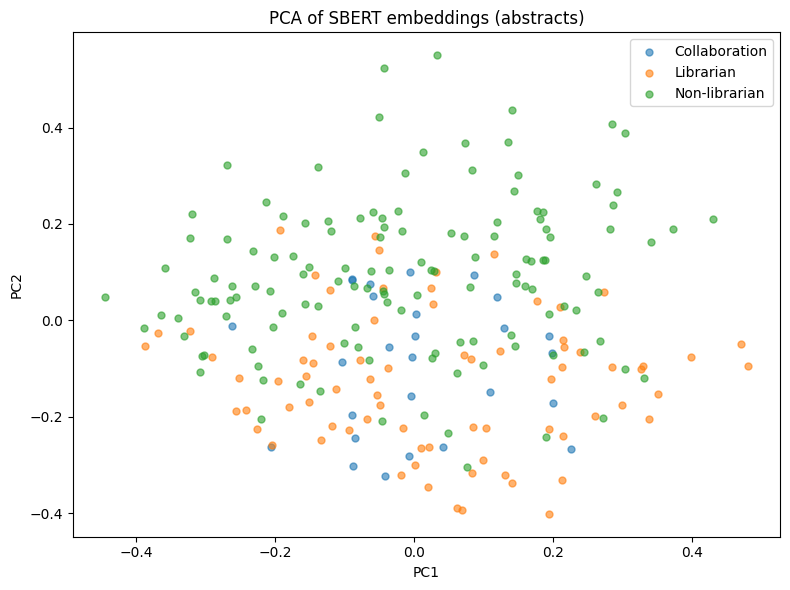

In [48]:
# PCA visualization of all abstracts in semantic space 
# emb is already L2-normalized (normalize_embeddings=True). PCA works on raw vectors regardless.

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(emb)

plot_df = WORK[["author_status"]].copy()
plot_df["pc1"] = coords[:,0]
plot_df["pc2"] = coords[:,1]

fig, ax = plt.subplots(figsize=(8,6))
for g, sub in plot_df.groupby("author_status"):
    ax.scatter(sub["pc1"], sub["pc2"], label=g, alpha=0.6, s=25)
ax.set_title("PCA of SBERT embeddings (abstracts)")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend()
plt.tight_layout()
plt.savefig("pca_sbert_abstracts.png", dpi=300, bbox_inches="tight")
plt.show()

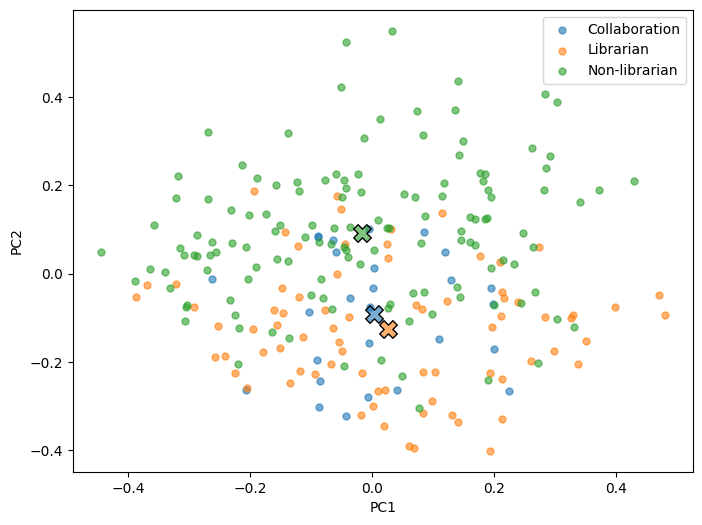

In [49]:
# --- PCA visualization of all abstracts in semantic space (with centroids) ---

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(emb)

plot_df = WORK[["author_status"]].copy()
plot_df["pc1"] = coords[:, 0]
plot_df["pc2"] = coords[:, 1]

fig, ax = plt.subplots(figsize=(8, 6))

# Plot points by group, and overlay centroid for each group
for g, sub in plot_df.groupby("author_status"):
    # scatter points
    sc = ax.scatter(sub["pc1"], sub["pc2"], label=g, alpha=0.6, s=25)

    # centroid (mean of coordinates)
    c1 = sub["pc1"].mean()
    c2 = sub["pc2"].mean()

    # use same color as the group's scatter
    color = sc.get_facecolor()[0]

    ax.scatter(
        [c1], [c2],
        s=160,
        marker="X",
        color=color,
        edgecolors="black",
        linewidths=1.0,
        zorder=5
    )

    # optional label slightly offset from the centroid
    # ax.annotate(
    #     f"{g} centroid",
    #     (c1, c2),
    #     xytext=(6, 6),
    #     textcoords="offset points",
    #     fontsize=9,
    #     weight="bold"
    # )

# ax.set_title("PCA of SBERT embeddings (abstracts) with centroids")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend()
plt.savefig("pca_sbert_abstracts_centroid.png", dpi=300, bbox_inches="tight")
plt.show()

In [50]:
# --- Permutation-based tests on similarity patterns ---
# Pairwise similarities are not independent, so we avoid t-tests on all pairs.
# Instead, we compute summary statistics from the full cosine-similarity matrix
# and permute document labels to generate a null distribution.

S = cosine_similarity(emb)  # (n_docs x n_docs)

def mean_pair_similarity(labels, g1, g2=None):
    idx1 = np.where(labels == g1)[0]
    if g2 is None or g2 == g1:
        # within-group: upper triangle without diagonal
        if len(idx1) < 2:
            return np.nan
        sub = S[np.ix_(idx1, idx1)]
        triu = sub[np.triu_indices_from(sub, k=1)]
        return float(np.mean(triu))
    idx2 = np.where(labels == g2)[0]
    if len(idx1) == 0 or len(idx2) == 0:
        return np.nan
    sub = S[np.ix_(idx1, idx2)]
    return float(np.mean(sub))

labels = WORK["author_status"].values

# Observed means
obs = {
    "AA_Librarian": mean_pair_similarity(labels, "Librarian"),
    "AA_NonLibrarian": mean_pair_similarity(labels, "Non-librarian"),
    "AA_Collab": mean_pair_similarity(labels, "Collaboration"),
    "AB_Lib_Non": mean_pair_similarity(labels, "Librarian", "Non-librarian"),
    "AB_Lib_Collab": mean_pair_similarity(labels, "Librarian", "Collaboration"),
    "AB_Non_Collab": mean_pair_similarity(labels, "Non-librarian", "Collaboration"),
}
pd.DataFrame([obs]).T.rename(columns={0:"mean_cosine_similarity"})

def perm_test_diff(labels, metric_fn, n_perm=2000, seed=42):
    rng = np.random.default_rng(seed)
    obs_val = metric_fn(labels)
    null = np.empty(n_perm, dtype=float)
    for i in range(n_perm):
        perm = rng.permutation(labels)
        null[i] = metric_fn(perm)
    # two-sided p-value
    p = (np.sum(np.abs(null - null.mean()) >= np.abs(obs_val - null.mean())) + 1) / (n_perm + 1)
    return obs_val, null.mean(), p


In [51]:
# 1) Are Librarian-within similarities higher than Librarian–NonLibrarian between similarities?
def metric_L_within_minus_between(lbls):
    return mean_pair_similarity(lbls, "Librarian") - mean_pair_similarity(lbls, "Librarian", "Non-librarian")

obs_val, null_mean, p_val = perm_test_diff(labels, metric_L_within_minus_between, n_perm=2000)
pd.DataFrame({"contrast":["within(Librarian) - between(Librarian,Non-librarian)"],
              "observed":[obs_val], "null_mean":[null_mean], "p_value":[p_val]})


,contrast,observed,null_mean,p_value
0,"within(Librarian) - between(Librarian,Non-libr...",0.060,0.000,0.000


In [52]:
# 2) Do Collaboration abstracts sit 'between' the two groups? (Non-librarian closer to Collab than Librarian is, or vice versa)
def metric_between_diff(lbls):
    return mean_pair_similarity(lbls, "Non-librarian", "Collaboration") - mean_pair_similarity(lbls, "Librarian", "Collaboration")

obs_val2, null_mean2, p_val2 = perm_test_diff(labels, metric_between_diff, n_perm=2000)
pd.DataFrame({"contrast":["between(Non-librarian,Collab) - between(Librarian,Collab)"],
              "observed":[obs_val2], "null_mean":[null_mean2], "p_value":[p_val2]})

,contrast,observed,null_mean,p_value
0,"between(Non-librarian,Collab) - between(Librar...",-0.053,-0.000,0.000


# Tables and Figures for manuscript

In [53]:
# ==============================
# EXPORT TABLES FOR MANUSCRIPT
# ==============================

# Create output directory
import os
OUTDIR = "paper_tables"
os.makedirs(OUTDIR, exist_ok=True)


# ------------------------------
# Table 1: Corpus composition by journal and author status
# ------------------------------
journal_pivot.to_csv(
    os.path.join(OUTDIR, "table1_corpus_composition.csv"),
    index=False
)


# ------------------------------
# Table 2: Descriptive statistics of abstract length
# ------------------------------
desc_overall.to_csv(
    os.path.join(OUTDIR, "table2a_abstract_overall.csv")
)

desc_by_status.to_csv(
    os.path.join(OUTDIR, "table2b_abstract_by_status.csv")
)


# ------------------------------
# Table 3: Authorship composition by journal
# ------------------------------
journal_pivot.to_csv(
    os.path.join(OUTDIR, "table3_authorship_by_journal.csv"),
    index=False
)


# ------------------------------
# Table 4: Aggregated composition by journal type
# ------------------------------
ct_prop.reset_index().to_csv(
    os.path.join(OUTDIR, "table4_journaltype_aggregate.csv"),
    index=False
)


# ------------------------------
# Table 5: Collaboration proportions by journal
# ------------------------------
collab_by_journal = (
    journal_pivot
      .assign(
          collaboration_prop=lambda x: x["Collaboration"] / x["total"]
      )
      [["journal_short", "journal_type_label", "Collaboration", "total", "collaboration_prop"]]
)

collab_by_journal.to_csv(
    os.path.join(OUTDIR, "table5_collaboration_by_journal.csv"),
    index=False
)


# ------------------------------
# Table 6: Top log-odds terms
# ------------------------------
# (Assumes you have created a DataFrame named `logodds_df`)
# If not, tell me and I’ll help you extract it

if "logodds_df" in globals():
    logodds_df.to_csv(
        os.path.join(OUTDIR, "table6_logodds_terms.csv"),
        index=False
    )
else:
    print("WARNING: logodds_df not found — Table 6 not exported.")


# ------------------------------
# Table 7: Classification performance
# ------------------------------
clf_results = pd.DataFrame({
    "cv_accuracy": cv_acc
})

clf_results.to_csv(
    os.path.join(OUTDIR, "table7_classifier_performance.csv"),
    index=False
)


# ------------------------------
# Table 8: Global metadata collocates
# ------------------------------
if "colloc_overall" in globals():
    colloc_overall.to_csv(
        os.path.join(OUTDIR, "table8_global_collocates.csv"),
        index=False
    )
else:
    print("WARNING: colloc_overall not found — Table 8 not exported.")


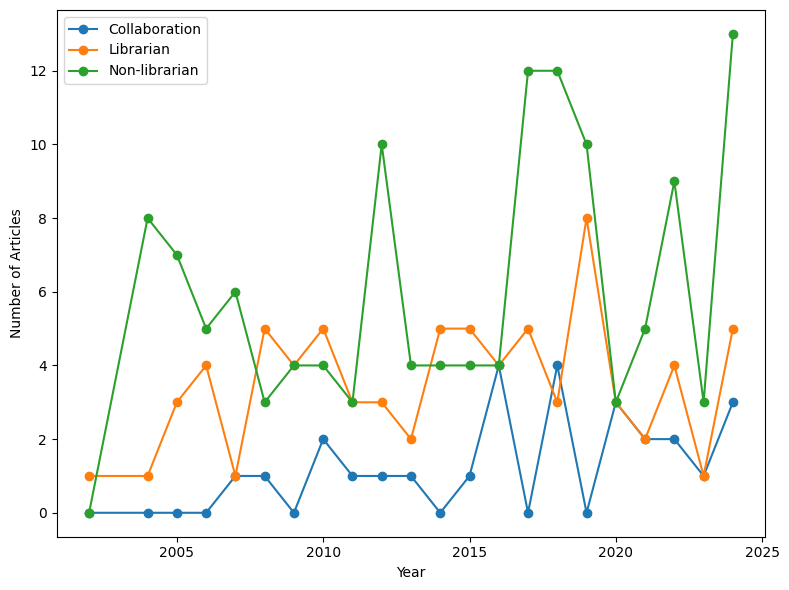

In [61]:
# Figure 1 — Annual Publication Trends (by Author Status)

import pandas as pd
import matplotlib.pyplot as plt

# Ensure year is numeric
WORK["year"] = WORK["year"].astype(int)

# Group by year and author_status
annual_counts = (
    WORK
    .groupby(["year", "author_status"])
    .size()
    .reset_index(name="n")   # <-- rename here
)

annual_counts.head()

annual_wide = (
    annual_counts
    .pivot(index="year", columns="author_status", values="n")
    .fillna(0)
    .reset_index()
)

annual_wide.head()

annual_wide.to_csv("paper_tables/figure1_annual_trends.csv", index=False)

# sanity check
WORK["author_status"].value_counts()
WORK["year"].min(), WORK["year"].max()

# Pivot for plotting
pivot = df.pivot(
    index="year",
    columns="author_status",
    values="n"
).fillna(0)

# Plot
plt.figure(figsize=(8, 6))

for status in pivot.columns:
    plt.plot(
        pivot.index,
        pivot[status],
        marker="o",
        label=status
    )

plt.xlabel("Year")
plt.ylabel("Number of Articles")
# plt.title("Annual Publication Trends by Author Status (2004–2024)")
plt.legend()

plt.tight_layout()

# Save
plt.savefig("figure1_annual_trends.png", dpi=300)
plt.show()


In [ ]:
# Figure 2 — Collaboration Rate Over Time

import pandas as pd
import matplotlib.pyplot as plt

# Load data
# Confirm directory location - i.e. in the previous cell, where was paper_tables created?
df = pd.read_csv("paper_tables/figure2_collaboration_trends.csv")

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    df["year"],
    df["collaboration_rate"],
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Proportion of Collaborative Articles")
plt.title("Collaboration Rate Over Time (2004–2024)")

plt.ylim(0, 1)

plt.tight_layout()

# Save
plt.savefig("figure2_collaboration_trends.png", dpi=300)
plt.show()
